In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
df=pd.read_csv(r'/content/diabetes_patients_10000_full.csv')

In [24]:
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [25]:
df.shape

(10000, 10)

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [27]:
df.isnull().sum()

,0
Patient_ID,0
Age,14
Gender,40
Blood_Sugar_Level,53
Creatinine,56
BMI,51
Urea,51
Cholesterol,32
HbA1c,0
Class,0


In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [30]:
df.drop(columns=['Patient_ID'], inplace=True)

In [31]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Blood_Sugar_Level'] = df['Blood_Sugar_Level'].fillna(df['Blood_Sugar_Level'].median())
df['Creatinine'] = df['Creatinine'].fillna(df['Creatinine'].median())
df['BMI'] = df['BMI'].fillna(df['BMI'].median())
df['Urea'] = df['Urea'].fillna(df['Urea'].median())
df['Cholesterol'] = df['Cholesterol'].fillna(df['Cholesterol'].median())

In [32]:
df['Gender'] = df['Gender'].map({
    'Male': 1,
    'Female': 0
})

<Axes: xlabel='Class', ylabel='count'>

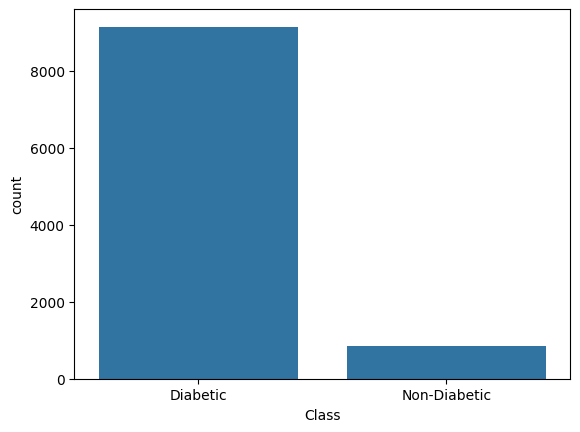

In [33]:
sns.countplot(data=df, x='Class')


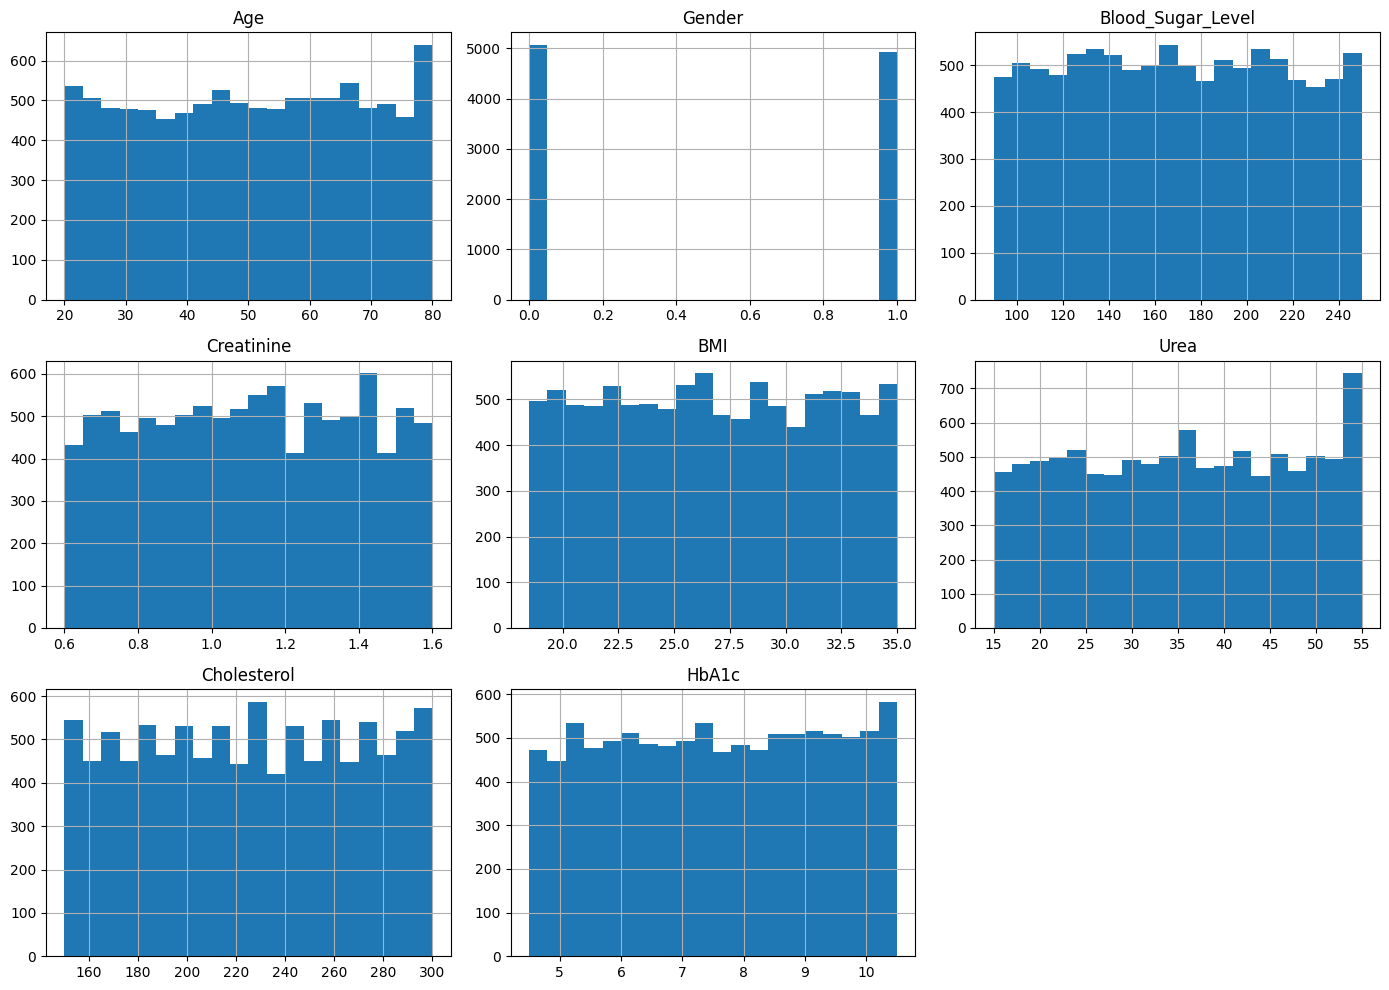

In [34]:
df.hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

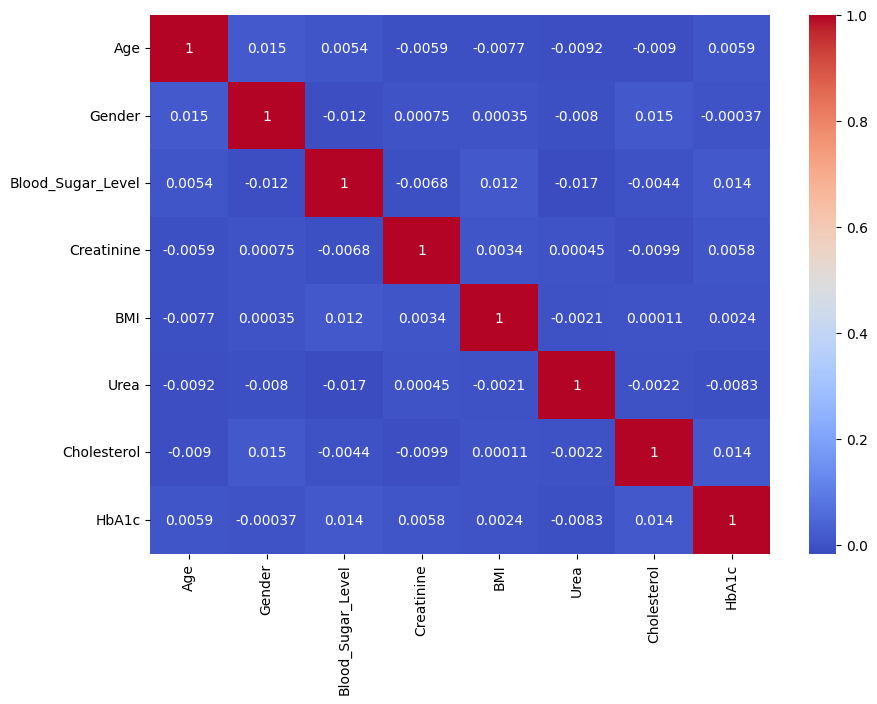

In [35]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

In [36]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Class'])
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [37]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
num_cols = df.drop(columns=['Class']).columns
df[num_cols] = scaler.fit_transform(df[num_cols])

In [39]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 49.2 MB/s  0:00:02


In [40]:
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [41]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


[Logistic Regression] Confusion Matrix:
 [[1811   18]
 [  39  132]]


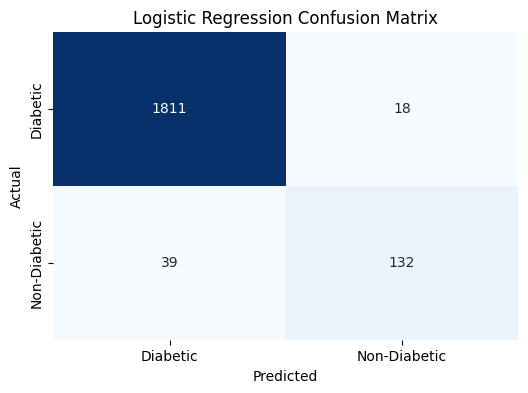


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.98      0.99      0.98      1829
Non-Diabetic       0.88      0.77      0.82       171

    accuracy                           0.97      2000
   macro avg       0.93      0.88      0.90      2000
weighted avg       0.97      0.97      0.97      2000

ROC-AUC: 0.9914790621532874


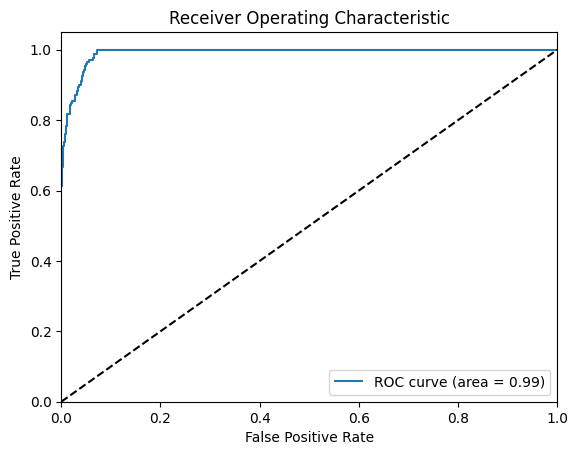

PR AUC: 0.9287467729824451


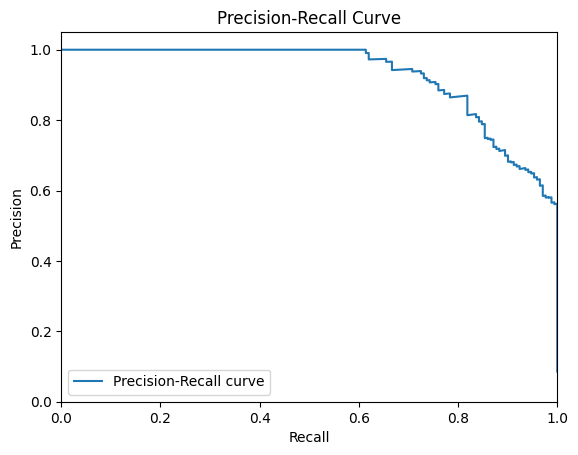

  8%|▊         | 1/13 [00:01<00:15,  1.30s/it]


[KNN] Confusion Matrix:
 [[1788   41]
 [ 147   24]]


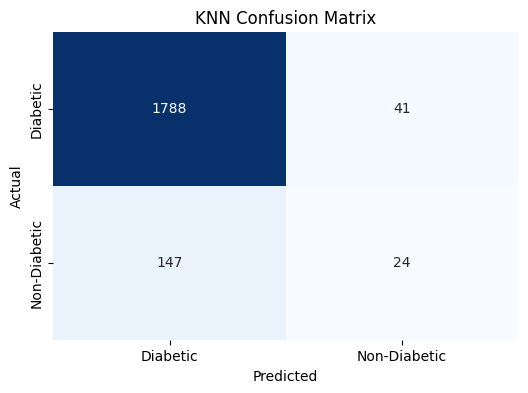


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.92      0.98      0.95      1829
Non-Diabetic       0.37      0.14      0.20       171

    accuracy                           0.91      2000
   macro avg       0.65      0.56      0.58      2000
weighted avg       0.88      0.91      0.89      2000

ROC-AUC: 0.8472753781665756


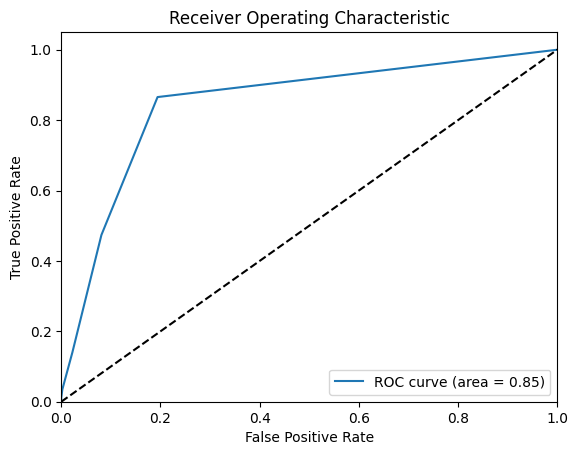

PR AUC: 0.30928621983855303


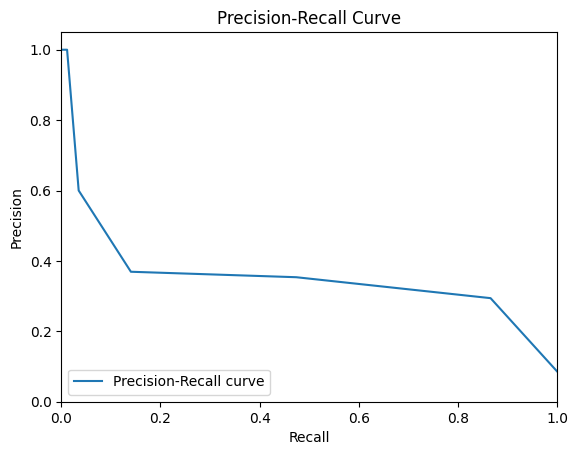

 15%|█▌        | 2/13 [00:02<00:12,  1.15s/it]


[SVC] Confusion Matrix:
 [[1829    0]
 [ 171    0]]


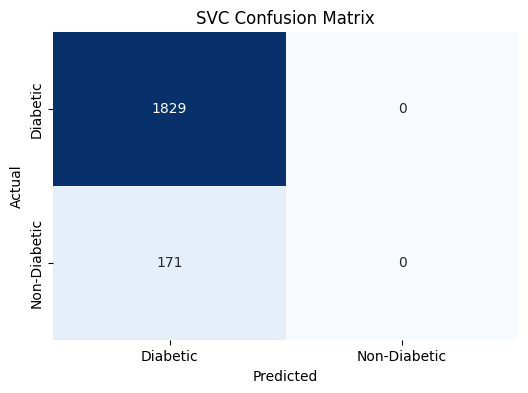


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.91      1.00      0.96      1829
Non-Diabetic       0.00      0.00      0.00       171

    accuracy                           0.91      2000
   macro avg       0.46      0.50      0.48      2000
weighted avg       0.84      0.91      0.87      2000

ROC-AUC: 0.9939490150563214


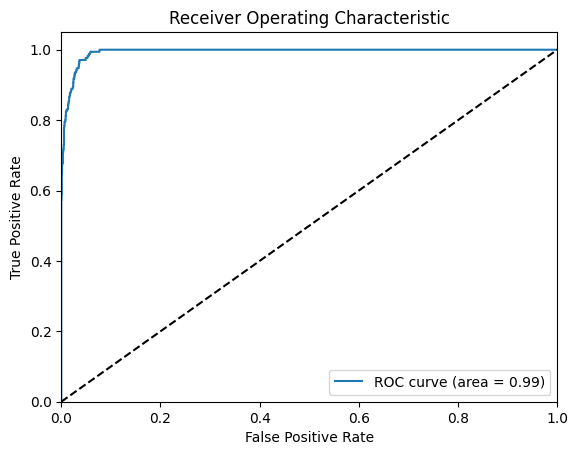

PR AUC: 0.9452378165748692


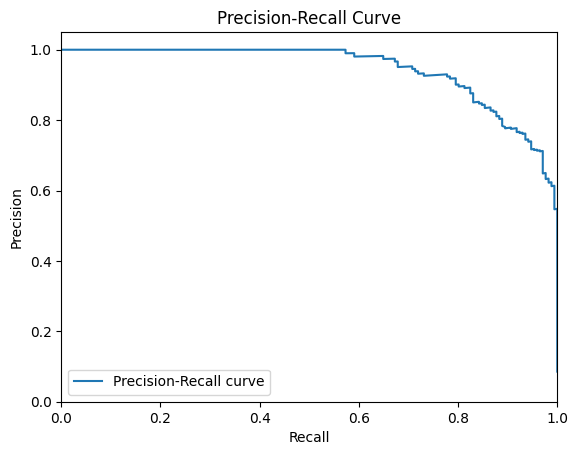

 23%|██▎       | 3/13 [00:08<00:33,  3.36s/it]


[Decision Tree] Confusion Matrix:
 [[1829    0]
 [   0  171]]


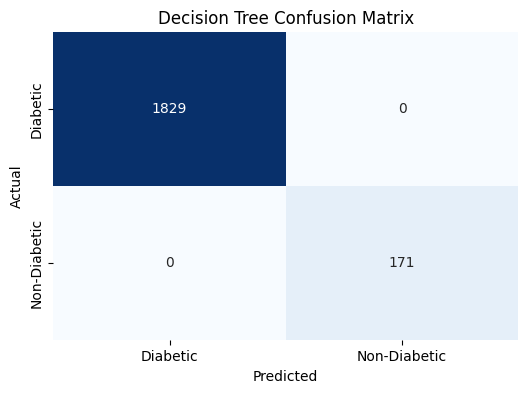


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1829
Non-Diabetic       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


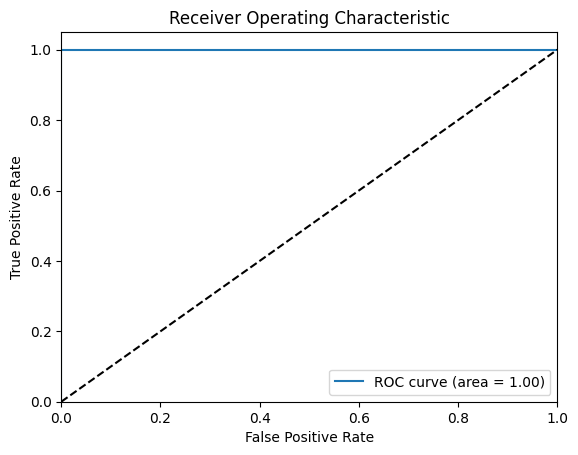

PR AUC: 1.0


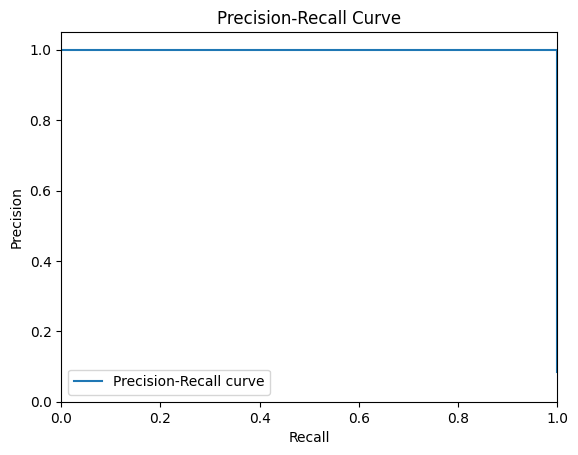

 31%|███       | 4/13 [00:09<00:21,  2.35s/it]


[Naive Bayes] Confusion Matrix:
 [[1829    0]
 [  24  147]]


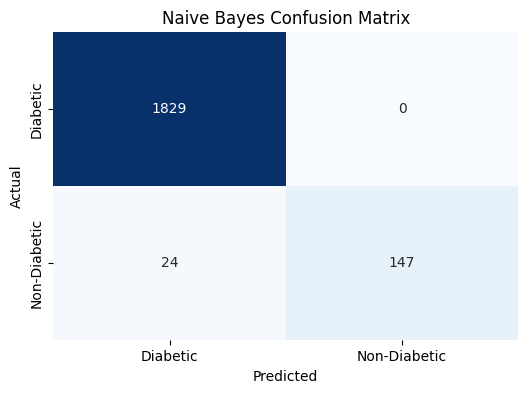


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.99      1.00      0.99      1829
Non-Diabetic       1.00      0.86      0.92       171

    accuracy                           0.99      2000
   macro avg       0.99      0.93      0.96      2000
weighted avg       0.99      0.99      0.99      2000

ROC-AUC: 0.9989800453384236


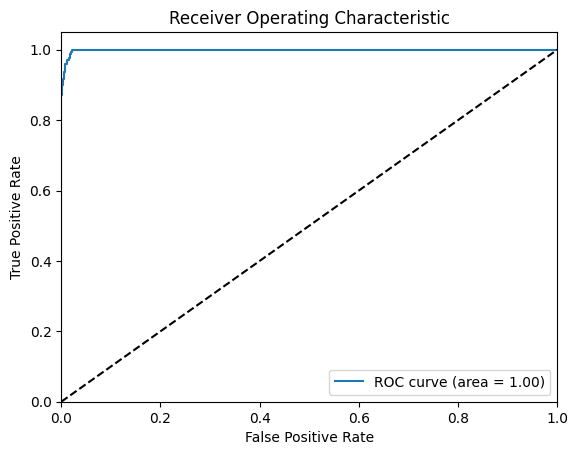

PR AUC: 0.9900712745574478


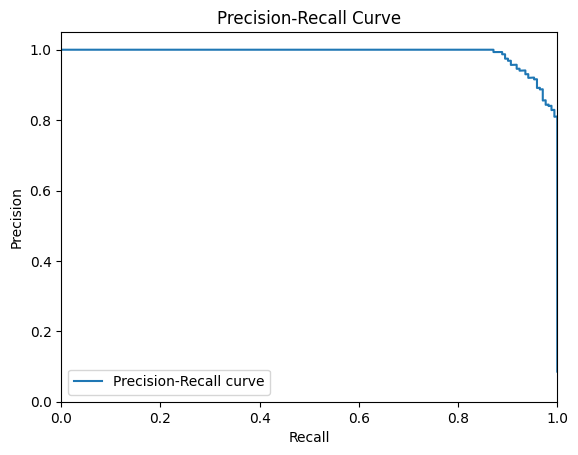

 38%|███▊      | 5/13 [00:09<00:14,  1.77s/it]


[Random Forest] Confusion Matrix:
 [[1829    0]
 [   0  171]]


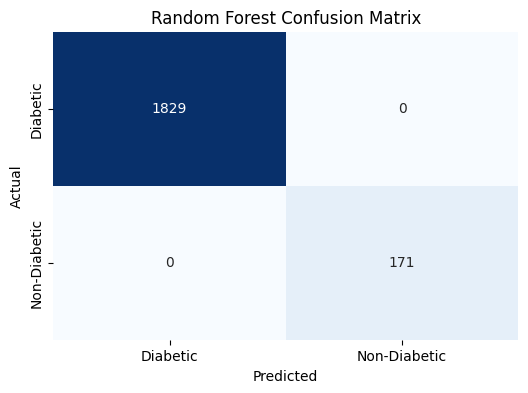


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1829
Non-Diabetic       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


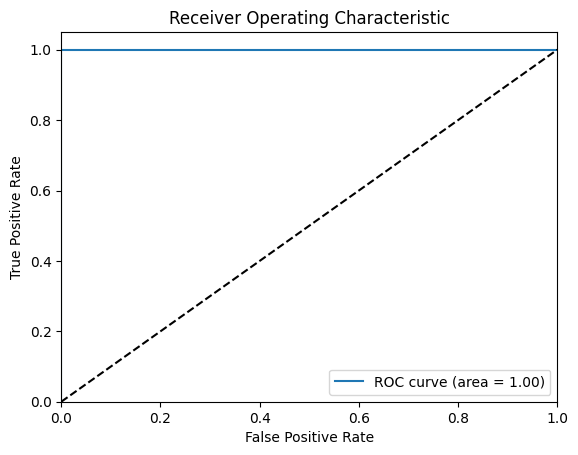

PR AUC: 1.0


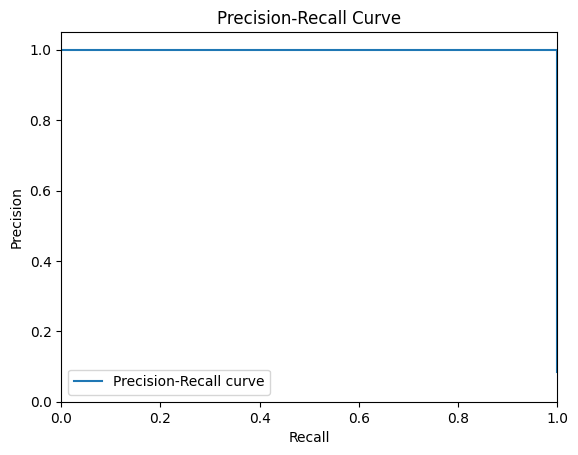

 46%|████▌     | 6/13 [00:11<00:10,  1.56s/it]


[Extra Trees] Confusion Matrix:
 [[1827    2]
 [  23  148]]


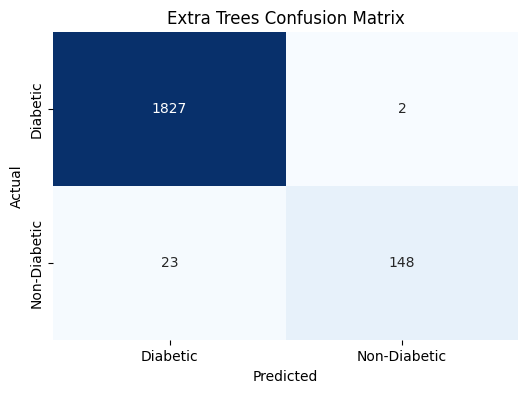


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.99      1.00      0.99      1829
Non-Diabetic       0.99      0.87      0.92       171

    accuracy                           0.99      2000
   macro avg       0.99      0.93      0.96      2000
weighted avg       0.99      0.99      0.99      2000

ROC-AUC: 0.9990935512647119


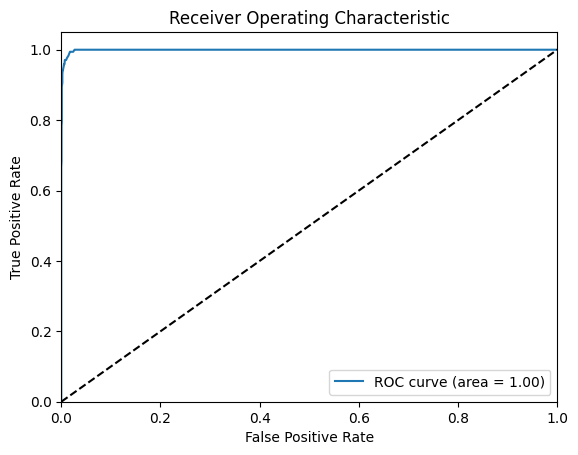

PR AUC: 0.9899880437146154


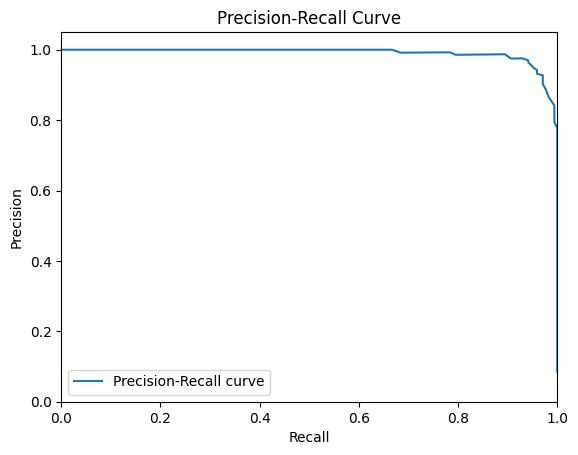

 54%|█████▍    | 7/13 [00:12<00:08,  1.43s/it]


[AdaBoost] Confusion Matrix:
 [[1829    0]
 [   0  171]]


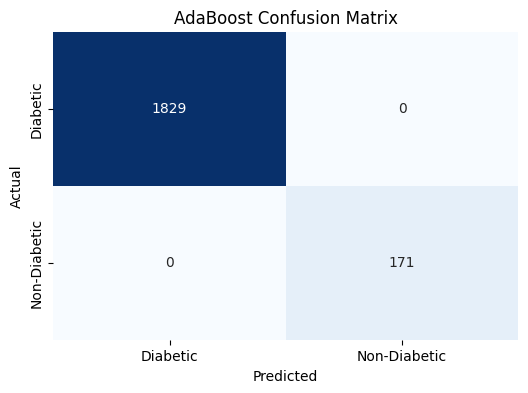


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1829
Non-Diabetic       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


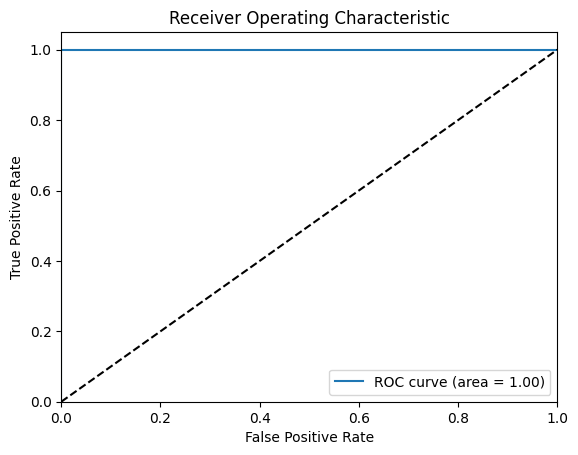

PR AUC: 0.9999999999999999


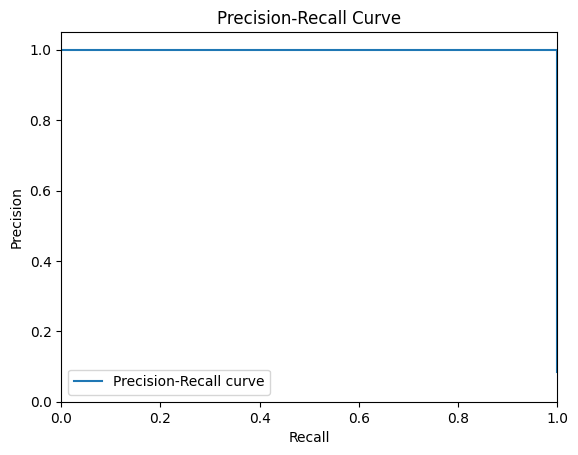

 62%|██████▏   | 8/13 [00:13<00:07,  1.41s/it]


[Gradient Boosting] Confusion Matrix:
 [[1829    0]
 [   0  171]]


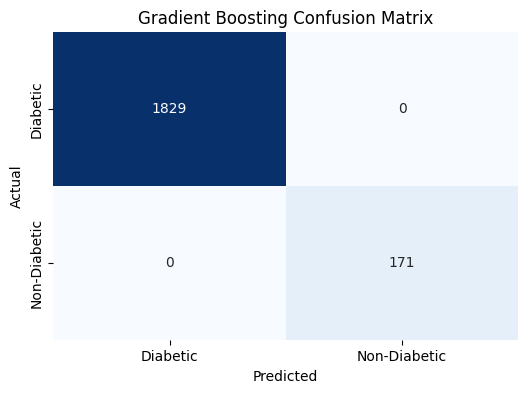


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1829
Non-Diabetic       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


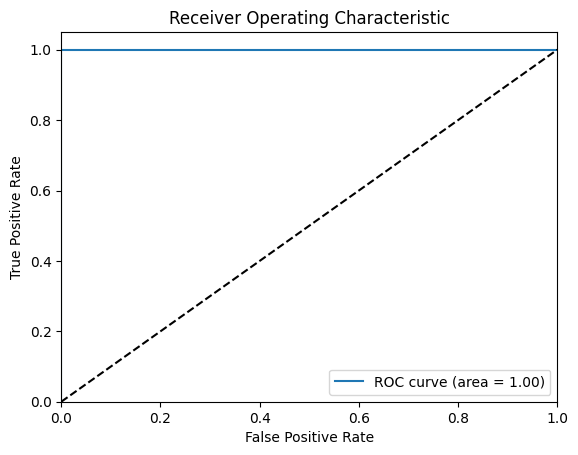

PR AUC: 1.0


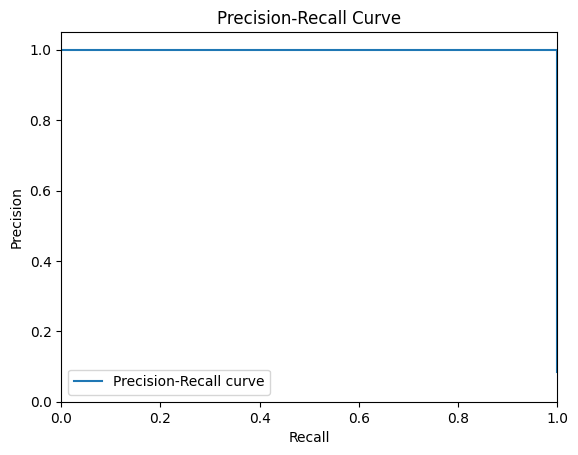

 69%|██████▉   | 9/13 [00:15<00:05,  1.48s/it]


[Hist Gradient Boosting] Confusion Matrix:
 [[1829    0]
 [   0  171]]


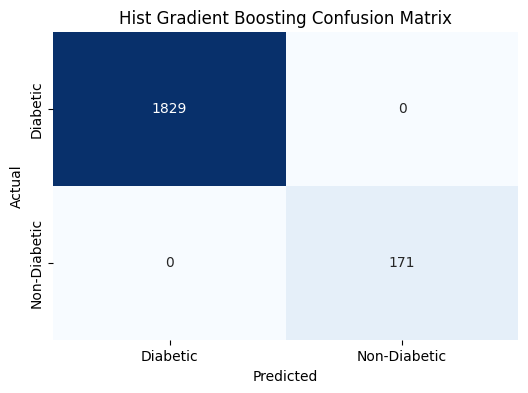


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1829
Non-Diabetic       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


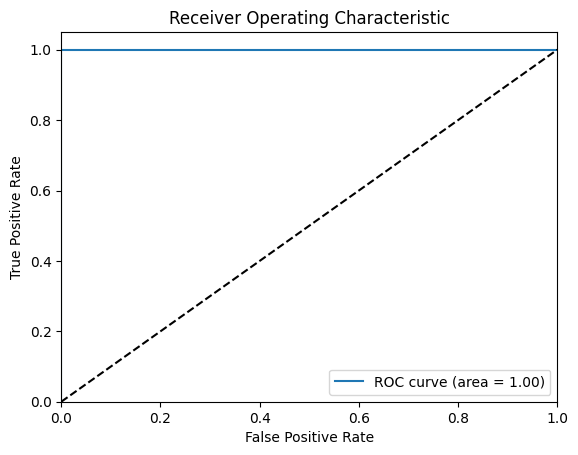

PR AUC: 1.0


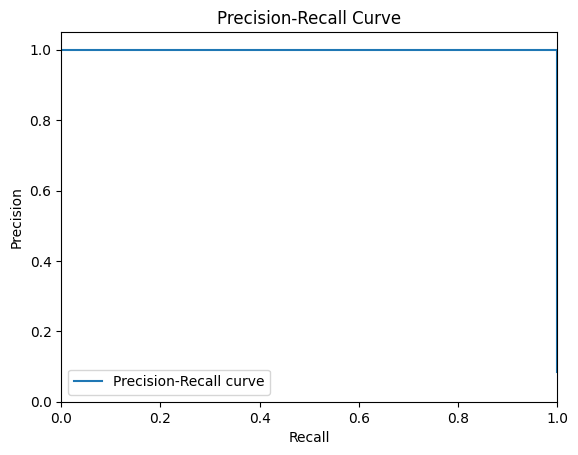

 77%|███████▋  | 10/13 [00:16<00:04,  1.61s/it]


ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['Diabetic' 'Non-Diabetic']

In [44]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    cm = confusion_matrix(y_test, test_pred)
    print(f"\n[{name}] Confusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
                xticklabels=['Diabetic', 'Non-Diabetic'],
                yticklabels=['Diabetic', 'Non-Diabetic'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title(f'{name} Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred, target_names=['Diabetic', 'Non-Diabetic'], zero_division=0))

    # Use predict_proba for ROC/PR metrics
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve with explicit pos_label
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='Non-Diabetic')
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    # PR AUC and curve with explicit pos_label
    pr_auc = average_precision_score(y_test == 'Non-Diabetic', y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label='Non-Diabetic')
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:08:24] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1829    0]
 [   0  171]]


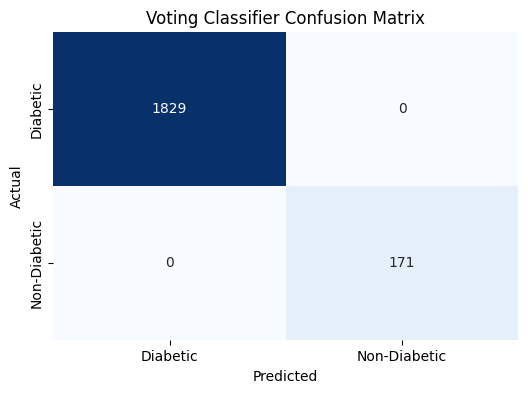


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1829
Non-Diabetic       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


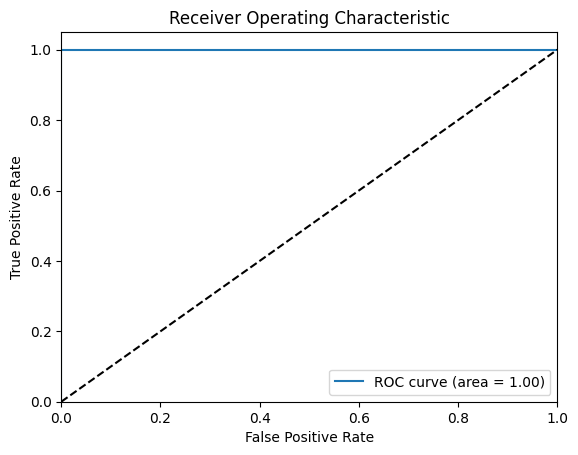

PR AUC: 1.0


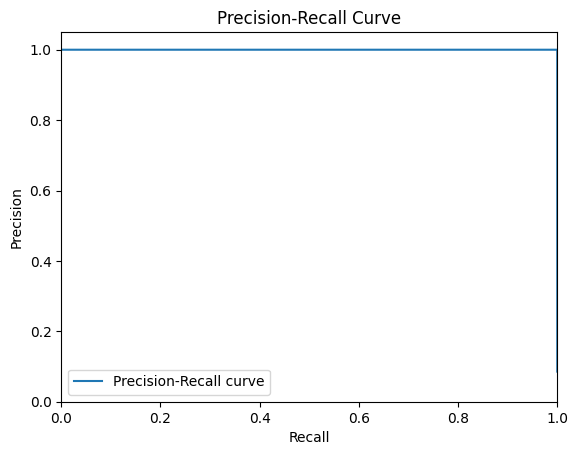

In [46]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft"
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)

cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
            xticklabels=['Diabetic', 'Non-Diabetic'],
            yticklabels=['Diabetic', 'Non-Diabetic'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Voting Classifier Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred, target_names=['Diabetic', 'Non-Diabetic'], zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve with explicit pos_label
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob, pos_label='Non-Diabetic')
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test == 'Non-Diabetic', y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob, pos_label='Non-Diabetic')
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred, pos_label='Non-Diabetic'),
    "Test Precision": precision_score(y_test, voting_test_pred, pos_label='Non-Diabetic'),
    "Train Recall": recall_score(y_train, voting_train_pred, pos_label='Non-Diabetic'),
    "Test Recall": recall_score(y_test, voting_test_pred, pos_label='Non-Diabetic'),
    "Train F1 Score": f1_score(y_train, voting_train_pred, pos_label='Non-Diabetic'),
    "Test F1 Score": f1_score(y_test, voting_test_pred, pos_label='Non-Diabetic'),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:08:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1829    0]
 [   0  171]]


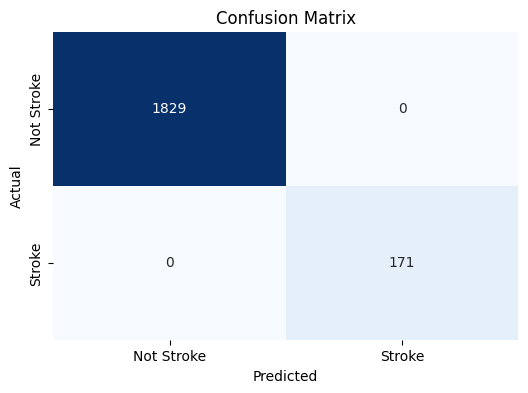


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1829
      Stroke       1.00      1.00      1.00       171

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


ValueError: y_true takes value in {'Diabetic', 'Non-Diabetic'} and pos_label is not specified: either make y_true take value in {0, 1} or {-1, 1} or pass pos_label explicitly.

In [47]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}